<a href="https://colab.research.google.com/github/Rajak20/Sales_Revenue_Prediction/blob/main/Sales_Revenue_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [ ]:
train_df.shape

(18000, 17)

In [ ]:
train_df.head()

,id,date,region,channel,product_category,customer_segment,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
0,1,2011-12-05 11:31:00,Nort,Search,General,Standard,9.00,0.75,0.2782,32.0,817,0.0010,3.34,1.000000,30.0,816.49,119.767811
1,2,2011-04-27 14:01:00,North,Social Media,General,Premium,3.35,3.35,0.0912,61.0,2289,0.0640,4.44,0.366025,90.0,1723.16,119.404661
2,3,2010-11-09 15:20:00,North,Affiliate,General,Budget,2.55,2.55,0.1997,461.0,14697,0.1508,3.31,0.366025,21.0,1151.74,132.009747
3,4,2010-10-03 15:24:00,North,Affiliate,Storage,Premium,2.95,2.95,0.4767,744.0,17578,0.1965,2.87,-0.366025,90.0,3585.85,154.511756
4,5,2011-10-14 09:28:00,North,Search,Lighting,Premium,15.00,1.25,0.3536,226.0,6280,0.0200,7.40,-0.366025,90.0,502.28,128.059924


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       18000 non-null  int64  
 1   date                     18000 non-null  object 
 2   region                   18000 non-null  object 
 3   channel                  18000 non-null  object 
 4   product_category         18000 non-null  object 
 5   customer_segment         18000 non-null  object 
 6   ad_spend                 17342 non-null  float64
 7   price                    18000 non-null  float64
 8   discount_rate            17245 non-null  float64
 9   market_reach             17314 non-null  float64
 10  impressions              18000 non-null  int64  
 11  click_through_rate       17287 non-null  float64
 12  competition_index        17293 non-null  float64
 13  seasonality_index        18000 non-null  float64
 14  campaign_duration_days

In [ ]:
train_df.describe()

,id,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
count,18000.000000,17342.000000,18000.000000,17245.000000,17314.000000,18000.000000,17287.000000,17293.000000,18000.000000,16487.000000,17257.000000,18000.000000
mean,9000.500000,44.071797,5.648265,0.230045,321.393323,7257.423889,0.057141,4.004004,-0.014902,35.565597,10317.172008,137.204937
std,5196.296758,190.165450,22.456661,0.149955,244.853653,7600.666112,0.049452,1.994997,0.919343,27.039417,35581.519328,54.961808
min,1.000000,0.180000,0.040000,0.000200,1.000000,-30771.000000,0.000000,0.040000,-1.366025,7.000000,0.550000,0.000000
25%,4500.750000,4.950000,1.250000,0.109500,138.000000,2503.750000,0.020450,2.440000,-1.000000,14.000000,573.110000,100.088209
50%,9000.500000,11.900000,1.950000,0.204000,269.000000,5106.500000,0.043500,3.870000,0.366025,28.000000,1781.440000,129.113361
75%,13500.250000,19.800000,3.750000,0.324900,439.000000,9566.250000,0.079900,5.410000,1.000000,60.000000,5502.780000,164.688454
max,18000.000000,4254.500000,295.000000,0.600000,1490.000000,173986.000000,0.435700,9.650000,1.366025,90.000000,543228.100000,684.320270


In [ ]:
test_df.shape

(6000, 16)

In [ ]:
test_df.head()

,id,date,region,channel,product_category,customer_segment,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value
0,18001,2010-11-14 13:39:00,North,Social Media,Storage,Premium,16.50,1.65,0.2763,845.0,16185,0.0637,6.32,0.366025,30.0,4500.10
1,18002,2010-10-10 11:53:00,North,Affiliate,Storage,Premium,15.00,1.25,0.1694,525.0,5684,0.0213,2.75,-0.366025,21.0,15.00
2,18003,2010-10-31 11:06:00,North,Social Media,General,Premium,325.44,3.39,0.3736,362.0,11490,0.0070,0.58,-0.366025,NaN,1818.31
3,18004,2011-02-07 14:51:00,South,Social Media,General,Premium,7.80,0.65,0.3246,138.0,3046,0.0686,1.50,1.366025,7.0,4442.36
4,18005,2011-05-16 14:24:00,north,Search,General,Premium,458.00,4.58,0.2625,309.0,8983,0.0231,9.19,-0.366025,28.0,400409.80


In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       6000 non-null   int64  
 1   date                     6000 non-null   object 
 2   region                   6000 non-null   object 
 3   channel                  6000 non-null   object 
 4   product_category         6000 non-null   object 
 5   customer_segment         6000 non-null   object 
 6   ad_spend                 5771 non-null   float64
 7   price                    6000 non-null   float64
 8   discount_rate            5720 non-null   float64
 9   market_reach             5765 non-null   float64
 10  impressions              6000 non-null   int64  
 11  click_through_rate       5738 non-null   float64
 12  competition_index        5754 non-null   float64
 13  seasonality_index        6000 non-null   float64
 14  campaign_duration_days  

In [ ]:
test_df.describe()

,id,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value
count,6000.000000,5771.000000,6000.000000,5720.000000,5765.000000,6000.000000,5738.000000,5754.000000,6000.000000,5551.000000,5735.000000
mean,21000.500000,44.895114,5.243418,0.226645,323.188205,7320.867167,0.056308,3.996940,-0.019712,36.277608,11089.574428
std,1732.195139,189.051655,20.082636,0.148512,247.362243,7613.079734,0.048878,2.013496,0.921995,27.219889,38838.379005
min,18001.000000,0.001000,0.001000,0.000200,1.000000,-18129.000000,0.000100,0.030000,-1.366025,7.000000,0.001000
25%,19500.750000,4.950000,1.250000,0.107800,141.000000,2474.000000,0.019725,2.410000,-1.000000,14.000000,559.395000
50%,21000.500000,12.600000,1.950000,0.199550,269.000000,5151.500000,0.042500,3.830000,0.366025,28.000000,1745.380000
75%,22500.250000,19.800000,3.750000,0.320925,439.000000,9701.750000,0.079275,5.460000,1.000000,60.000000,5319.725000
max,24000.000000,2500.000000,246.834153,0.600000,1490.000000,118268.000000,0.334200,9.590000,1.366025,90.000000,594023.990000


In [ ]:
# Inspect unique values in categorical columns
print("Before cleaning:")
print("Train regions:", train_df['region'].unique())
print("Test regions:", test_df['region'].unique())

# Standardize casing and correct common typos
for df in [train_df, test_df]:
    df['region'] = df['region'].str.strip().str.title()
    df['region'] = df['region'].replace({'Nort': 'North','Norht':'North'})

    df['channel'] = df['channel'].str.strip().str.title()
    df['product_category'] = df['product_category'].str.strip().str.title()
    df['customer_segment'] = df['customer_segment'].str.strip().str.title()

print("\nAfter cleaning:")
print("Train regions:", train_df['region'].unique())
print("Test regions:", test_df['region'].unique())

Before cleaning:
Train regions: ['Nort' 'North' 'north' 'NORTH' 'Central' 'Norht' 'north ' 'East' 'West'
 'South']
Test regions: ['North' 'South' 'north ' 'Nort' 'West' 'East' 'north' 'Central' 'Norht'
 'NORTH']

After cleaning:
Train regions: ['North' 'Central' 'East' 'West' 'South']
Test regions: ['North' 'South' 'West' 'East' 'Central']


In [ ]:
# Handle negative values in impressions
for df in [train_df, test_df]:
    df['impressions'] = df['impressions'].abs()

print("Train impressions min:", train_df['impressions'].min())
print("Test impressions min:", test_df['impressions'].min())

Train impressions min: 10
Test impressions min: 25


In [ ]:
# Check missing values
print("Missing values in Train:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

# Impute missing values with column medians
num_cols_with_nan = ['ad_spend', 'discount_rate', 'market_reach', 'click_through_rate',
                     'competition_index', 'campaign_duration_days', 'customer_lifetime_value']

for col in num_cols_with_nan:
    median_val = train_df[col].median()
    train_df[col] = train_df[col].fillna(median_val)
    test_df[col] = test_df[col].fillna(median_val)

print("\nRemaining missing values in Train after imputation:", train_df.isnull().sum().sum())
print("Remaining missing values in Test after imputation:", test_df.isnull().sum().sum())

Missing values in Train:
ad_spend                    658
discount_rate               755
market_reach                686
click_through_rate          713
competition_index           707
campaign_duration_days     1513
customer_lifetime_value     743
dtype: int64

Remaining missing values in Train after imputation: 0
Remaining missing values in Test after imputation: 0


In [ ]:
# Inspect current unique values in remaining categorical columns
for col in ['channel', 'product_category', 'customer_segment']:
    print(f"--- Unique values in '{col}' before standardizing ---")
    print("Train:", train_df[col].unique())
    print("Test:", test_df[col].unique())
    print()

--- Unique values in 'channel' before standardizing ---
Train: ['Search' 'Social Media' 'Affiliate' 'Email' 'Tv' 'Influencer'
 'Social_Media' 'Socail Media' 'Socialmedia']
Test: ['Social Media' 'Affiliate' 'Search' 'Tv' 'Influencer' 'Email'
 'Socialmedia' 'Social_Media' 'Socail Media']

--- Unique values in 'product_category' before standardizing ---
Train: ['General' 'Storage' 'Lighting' 'Stationery' 'Kitchen' 'Seasonal']
Test: ['Storage' 'General' 'Stationery' 'Kitchen' 'Seasonal' 'Lighting']

--- Unique values in 'customer_segment' before standardizing ---
Train: ['Standard' 'Premium' 'Budget']
Test: ['Premium' 'Budget' 'Standard']



In [ ]:
# Perform standardization and fix typos
for df in [train_df, test_df]:
    for col in ['channel', 'product_category', 'customer_segment']:
        # Convert to title case and strip whitespace
        df[col] = df[col].astype(str).str.strip().str.title()

    # Dictionary mappings for potential misspelled versions we might find
    df['channel'] = df['channel'].replace({
        'Seach': 'Search',
        'Serch': 'Search',
        'Socialmedia': 'Social Media',
        'Emailmarketing': 'Email'
    })
    df['product_category'] = df['product_category'].replace({
        'Generl': 'General',
        'Lightng': 'Lighting',
        'Storag': 'Storage'
    })
    df['customer_segment'] = df['customer_segment'].replace({
        'Stndard': 'Standard',
        'Premum': 'Premium',
        'Budgt': 'Budget'
    })

# Verify the cleaning results
for col in ['channel', 'product_category', 'customer_segment']:
    print(f"--- Unique values in '{col}' after cleaning ---")
    print("Train:", train_df[col].unique())
    print("Test:", test_df[col].unique())
    print()

--- Unique values in 'channel' after cleaning ---
Train: ['Search' 'Social Media' 'Affiliate' 'Email' 'Tv' 'Influencer'
 'Social_Media' 'Socail Media']
Test: ['Social Media' 'Affiliate' 'Search' 'Tv' 'Influencer' 'Email'
 'Social_Media' 'Socail Media']

--- Unique values in 'product_category' after cleaning ---
Train: ['General' 'Storage' 'Lighting' 'Stationery' 'Kitchen' 'Seasonal']
Test: ['Storage' 'General' 'Stationery' 'Kitchen' 'Seasonal' 'Lighting']

--- Unique values in 'customer_segment' after cleaning ---
Train: ['Standard' 'Premium' 'Budget']
Test: ['Premium' 'Budget' 'Standard']



In [ ]:
train_df['channel'].unique()

array(['Search', 'Social Media', 'Affiliate', 'Email', 'Tv', 'Influencer',
       'Social_Media', 'Socail Media'], dtype=object)

In [ ]:
train_df['product_category'].unique()

array(['General', 'Storage', 'Lighting', 'Stationery', 'Kitchen',
       'Seasonal'], dtype=object)

In [ ]:
train_df['customer_segment'].unique()

array(['Standard', 'Premium', 'Budget'], dtype=object)

In [ ]:
for df in [train_df, test_df]:
    # Map inconsistent variants of Social Media
    df['channel'] = df['channel'].replace({
        'Social Media': 'Social_Media',
        'Socail Media': 'Social_Media'
    })

# Verify the final unique values in 'channel'
print("Train channels:", train_df['channel'].unique())
print("Test channels:", test_df['channel'].unique())

Train channels: ['Search' 'Social_Media' 'Affiliate' 'Email' 'Tv' 'Influencer']
Test channels: ['Social_Media' 'Affiliate' 'Search' 'Tv' 'Influencer' 'Email']


In [ ]:
# Double-check missing values across all columns in train and test datasets
print("Initial missing values in Train:")
print(train_df.isnull().sum())
print("\nInitial missing values in Test:")
print(test_df.isnull().sum())

# Identify numerical and categorical columns with missing values
for df in [train_df, test_df]:
    for col in df.columns:
        if df[col].isnull().any():
            if df[col].dtype in ['float64', 'int64']:
                # Fill numerical columns with median from the train set to prevent data leakage
                median_val = train_df[col].median()
                df[col] = df[col].fillna(median_val)
            else:
                # Fill categorical columns with mode from the train set
                mode_val = train_df[col].mode()[0]
                df[col] = df[col].fillna(mode_val)

# Final validation
print("\n--- Verification after filling ---")
print("Remaining missing values in Train:", train_df.isnull().sum().sum())
print("Remaining missing values in Test:", test_df.isnull().sum().sum())

Initial missing values in Train:
id                         0
date                       0
region                     0
channel                    0
product_category           0
customer_segment           0
ad_spend                   0
price                      0
discount_rate              0
market_reach               0
impressions                0
click_through_rate         0
competition_index          0
seasonality_index          0
campaign_duration_days     0
customer_lifetime_value    0
sales_revenue              0
dtype: int64

Initial missing values in Test:
id                         0
date                       0
region                     0
channel                    0
product_category           0
customer_segment           0
ad_spend                   0
price                      0
discount_rate              0
market_reach               0
impressions                0
click_through_rate         0
competition_index          0
seasonality_index          0
campaign_duration_days

In [ ]:
# Calculate and display summary statistics for numerical columns in train_df
numerical_summary = train_df.describe(include=[np.number])
display(numerical_summary)

,id,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
count,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000
mean,9000.500000,42.895739,5.648265,0.228952,319.396556,7309.363556,0.056600,3.998741,-0.014902,34.929667,9964.835959,137.204937
std,5196.296758,186.754718,22.456661,0.146869,240.351686,7550.727728,0.048536,1.955596,0.919343,25.963015,34880.733586,54.961808
min,1.000000,0.180000,0.040000,0.000200,1.000000,10.000000,0.000000,0.040000,-1.366025,7.000000,0.550000,0.000000
25%,4500.750000,4.950000,1.250000,0.113200,142.000000,2527.000000,0.021300,2.500000,-1.000000,14.000000,606.397500,100.088209
50%,9000.500000,11.900000,1.950000,0.204000,269.000000,5127.500000,0.043500,3.870000,0.366025,28.000000,1781.440000,129.113361
75%,13500.250000,19.500000,3.750000,0.318900,428.000000,9592.500000,0.077700,5.350000,1.000000,60.000000,5215.275000,164.688454
max,18000.000000,4254.500000,295.000000,0.600000,1490.000000,173986.000000,0.435700,9.650000,1.366025,90.000000,543228.100000,684.320270


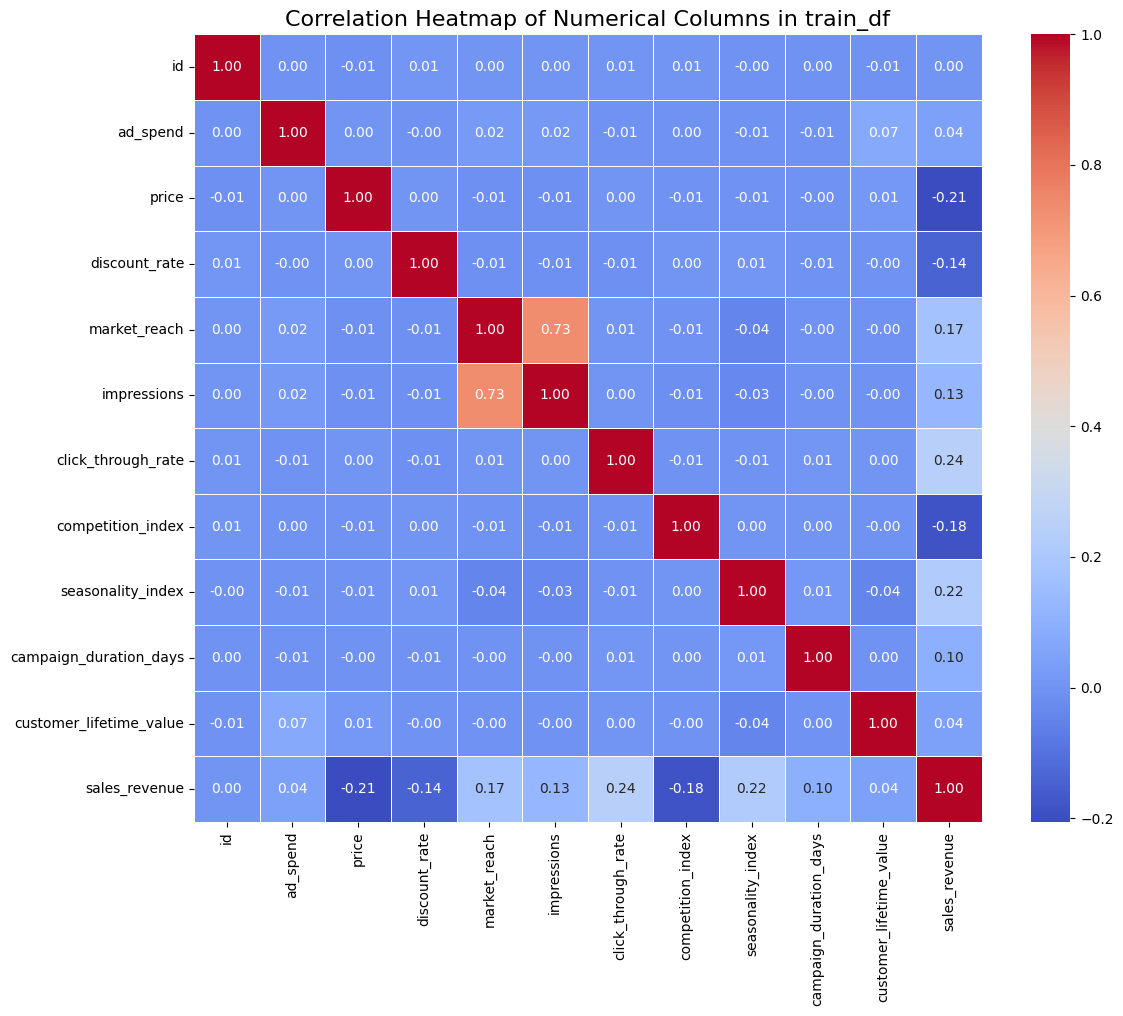

In [ ]:
# Calculate the correlation matrix for numerical columns in train_df
numerical_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numerical_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Columns in train_df", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Identify target and preserve ID columns
target = train_df['sales_revenue']
train_ids = train_df['id']
test_ids = test_df['id']

# Combine datasets briefly to ensure matching categories during encoding
categorical_cols = ['region', 'channel', 'product_category', 'customer_segment']
combined_df = pd.concat([train_df.drop(columns=['sales_revenue']), test_df], axis=0)

# One-hot encode the categorical columns
combined_encoded = pd.get_dummies(combined_df, columns=categorical_cols, drop_first=True)

# Split back into train and test sets
train_encoded = combined_encoded.iloc[:len(train_df)].copy()
test_encoded = combined_encoded.iloc[len(train_df):].copy()

# Re-attach target to train_encoded
train_encoded['sales_revenue'] = target

# Display the new shapes and a preview of the encoded train dataframe
print("Encoded Train shape:", train_encoded.shape)
print("Encoded Test shape:", test_encoded.shape)
display(train_encoded.head())

Encoded Train shape: (18000, 29)
Encoded Test shape: (6000, 28)


,id,date,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,...,channel_Social_Media,channel_Tv,product_category_Kitchen,product_category_Lighting,product_category_Seasonal,product_category_Stationery,product_category_Storage,customer_segment_Premium,customer_segment_Standard,sales_revenue
0,1,2011-12-05 11:31:00,9.00,0.75,0.2782,32.0,817,0.0010,3.34,1.000000,...,False,False,False,False,False,False,False,False,True,119.767811
1,2,2011-04-27 14:01:00,3.35,3.35,0.0912,61.0,2289,0.0640,4.44,0.366025,...,True,False,False,False,False,False,False,True,False,119.404661
2,3,2010-11-09 15:20:00,2.55,2.55,0.1997,461.0,14697,0.1508,3.31,0.366025,...,False,False,False,False,False,False,False,False,False,132.009747
3,4,2010-10-03 15:24:00,2.95,2.95,0.4767,744.0,17578,0.1965,2.87,-0.366025,...,False,False,False,False,False,False,True,True,False,154.511756
4,5,2011-10-14 09:28:00,15.00,1.25,0.3536,226.0,6280,0.0200,7.40,-0.366025,...,False,False,False,True,False,False,False,True,False,128.059924


In [ ]:
bool_cols = train_encoded.select_dtypes(include=['bool']).columns

train_encoded[bool_cols] = train_encoded[bool_cols].astype(int)
test_encoded[bool_cols] = test_encoded[bool_cols].astype(int)

display(train_encoded.head())

,id,date,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,...,channel_Social_Media,channel_Tv,product_category_Kitchen,product_category_Lighting,product_category_Seasonal,product_category_Stationery,product_category_Storage,customer_segment_Premium,customer_segment_Standard,sales_revenue
0,1,2011-12-05 11:31:00,9.00,0.75,0.2782,32.0,817,0.0010,3.34,1.000000,...,0,0,0,0,0,0,0,0,1,119.767811
1,2,2011-04-27 14:01:00,3.35,3.35,0.0912,61.0,2289,0.0640,4.44,0.366025,...,1,0,0,0,0,0,0,1,0,119.404661
2,3,2010-11-09 15:20:00,2.55,2.55,0.1997,461.0,14697,0.1508,3.31,0.366025,...,0,0,0,0,0,0,0,0,0,132.009747
3,4,2010-10-03 15:24:00,2.95,2.95,0.4767,744.0,17578,0.1965,2.87,-0.366025,...,0,0,0,0,0,0,1,1,0,154.511756
4,5,2011-10-14 09:28:00,15.00,1.25,0.3536,226.0,6280,0.0200,7.40,-0.366025,...,0,0,0,1,0,0,0,1,0,128.059924


In [ ]:
# Calculate correlations of all numerical/encoded features with sales_revenue
numeric_train = train_encoded.select_dtypes(include=[np.number])
correlations = numeric_train.corr()['sales_revenue'].sort_values(ascending=False)

print("Correlation of all columns with sales_revenue:")
print(correlations)

Correlation of all columns with sales_revenue:
sales_revenue                  1.000000
click_through_rate             0.242433
seasonality_index              0.221127
market_reach                   0.173273
product_category_Stationery    0.136123
impressions                    0.128324
channel_Social_Media           0.127804
campaign_duration_days         0.097785
channel_Influencer             0.096290
product_category_Storage       0.080709
channel_Search                 0.046363
customer_lifetime_value        0.041493
ad_spend                       0.039323
product_category_Seasonal      0.036654
customer_segment_Premium       0.033100
region_North                   0.013883
region_West                    0.003032
id                             0.002889
region_East                   -0.005943
region_South                  -0.021278
product_category_Kitchen      -0.025747
customer_segment_Standard     -0.026285
product_category_Lighting     -0.038414
channel_Email                 -0.

In [ ]:
# Define columns to drop based on low correlation (< 0.05 absolute correlation) and metadata status
cols_to_drop = [
    'id', 'date', 'customer_lifetime_value', 'ad_spend', 'channel_Search',
    'product_category_Seasonal', 'customer_segment_Premium', 'region_North',
    'region_West', 'region_East', 'region_South', 'product_category_Kitchen',
    'customer_segment_Standard', 'product_category_Lighting'
]

# Drop columns present in the datasets
train_final = train_encoded.drop(columns=[col for col in cols_to_drop if col in train_encoded.columns])
test_final = test_encoded.drop(columns=[col for col in cols_to_drop if col in test_encoded.columns])

print("Remaining columns in Train:", list(train_final.columns))
print("Remaining columns in Test:", list(test_final.columns))
print("Train shape:", train_final.shape)
print("Test shape:", test_final.shape)

Remaining columns in Train: ['price', 'discount_rate', 'market_reach', 'impressions', 'click_through_rate', 'competition_index', 'seasonality_index', 'campaign_duration_days', 'channel_Email', 'channel_Influencer', 'channel_Social_Media', 'channel_Tv', 'product_category_Stationery', 'product_category_Storage', 'sales_revenue']
Remaining columns in Test: ['price', 'discount_rate', 'market_reach', 'impressions', 'click_through_rate', 'competition_index', 'seasonality_index', 'campaign_duration_days', 'channel_Email', 'channel_Influencer', 'channel_Social_Media', 'channel_Tv', 'product_category_Stationery', 'product_category_Storage']
Train shape: (18000, 15)
Test shape: (6000, 14)


In [ ]:
x = train_final.drop('sales_revenue',axis=1)
y = train_final[['sales_revenue']]

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical features that need scaling (excluding encoded 0/1 binary columns)
# Although scaling binary columns is sometimes done, it's generally best to scale the continuous features
continuous_cols = ['price', 'discount_rate', 'market_reach', 'impressions', 'click_through_rate', 'competition_index', 'seasonality_index', 'campaign_duration_days']

# Initialize scale
scaler = StandardScaler()

# Create copies to preserve original datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
test_final_scaled = test_final.copy()

# Fit on X_train and transform train/test splits
X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

# Scale full dataset 'x' and 'test_final' for final submission predictions
full_scaler = StandardScaler()
x_scaled = x.copy()
x_scaled[continuous_cols] = full_scaler.fit_transform(x[continuous_cols])
test_final_scaled[continuous_cols] = full_scaler.transform(test_final[continuous_cols])

# Display preview of scaled training features
display(X_train_scaled.head())

,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,channel_Email,channel_Influencer,channel_Social_Media,channel_Tv,product_category_Stationery,product_category_Storage
8962,-0.158816,-1.088889,0.015790,-0.139256,0.442442,0.863852,-1.071577,0.965922,0,0,0,0,0,0
4520,-0.212271,1.958003,-0.221560,-0.346709,0.419800,0.314842,0.414632,0.965922,0,0,1,0,0,0
14957,3.969380,-1.118887,0.453014,0.047400,-0.360344,-1.922245,-1.071577,-0.534957,0,1,0,0,0,0
2992,-0.195165,0.522848,1.539826,2.859717,-0.850249,-0.157204,-0.381825,2.120444,0,0,1,0,0,1
10498,-0.212271,2.324802,-1.037710,-0.750567,0.586532,-1.311664,-1.469805,-0.534957,0,0,1,0,0,0


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
le = LinearRegression()
model = le.fit(X_train_scaled, y_train)
model

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
r2_score(y_test,y_pred)

0.3043038580753763

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor
# We'll set a random_state for reproducibility and use n_estimators=100 as a starting point
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Train the model
rf_model.fit(X_train_scaled, y_train.values.ravel())

# Predict on the test split
y_pred_rf = rf_model.predict(X_test_scaled)

# Calculate and print the R2 score
rf_r2 = r2_score(y_test, y_pred_rf)
print(f"Random Forest Regressor R2 Score: {rf_r2:.4f}")

Random Forest Regressor R2 Score: 0.8891


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Instantiate a new Random Forest model to train on the complete dataset
rf_final = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Train on the full scaled training dataset
rf_final.fit(x_scaled, y.values.ravel())

# Predict on the scaled test dataset (new inputs)
test_predictions = rf_final.predict(test_final_scaled)

# Combine ID with the predicted sales_revenue
submission_df = pd.DataFrame({
    'id': test_ids,
    'predicted_sales_revenue': test_predictions
})

# Display some sample predictions
display(submission_df.head())

# Save to csv
submission_df.to_csv('predictions.csv', index=False)
print("Predictions saved successfully to 'predictions.csv'!")

,id,predicted_sales_revenue
0,18001,168.916101
1,18002,165.824482
2,18003,122.991116
3,18004,184.994644
4,18005,83.878757


Predictions saved successfully to 'predictions.csv'!


In [ ]:
# Print column list of both dataframes to inspect mismatch
train_cols = list(x_scaled.columns)
test_cols = list(test_final_scaled.columns)

print("Columns in x_scaled:", train_cols)
print("Columns in test_final_scaled:", test_cols)
print("Mismatch (In Train but not Test):", set(train_cols) - set(test_cols))
print("Mismatch (In Test but not Train):", set(test_cols) - set(train_cols))

Columns in x_scaled: ['price', 'discount_rate', 'market_reach', 'impressions', 'click_through_rate', 'competition_index', 'seasonality_index', 'campaign_duration_days', 'channel_Email', 'channel_Influencer', 'channel_Social_Media', 'channel_Tv', 'product_category_Stationery', 'product_category_Storage']
Columns in test_final_scaled: ['price', 'discount_rate', 'market_reach', 'impressions', 'click_through_rate', 'competition_index', 'seasonality_index', 'campaign_duration_days', 'channel_Email', 'channel_Influencer', 'channel_Social_Media', 'channel_Tv', 'product_category_Stationery', 'product_category_Storage']
Mismatch (In Train but not Test): set()
Mismatch (In Test but not Train): set()


In [ ]:
import pickle
from google.colab import files

# Safely serialize and save the model and scaler to the disk
with open('random_forest_model.pkl', 'wb') as file:
    pickle.dump(rf_final, file)

with open('scaler.pkl', 'wb') as file:
    pickle.dump(full_scaler, file)

# Download the generated files
files.download('predictions.csv')
files.download('random_forest_model.pkl')
files.download('scaler.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>